# 3 — Voisins, gradients et information en amont du vent

**Question :** Les cellules situées à environ 75 ou 200 km permettent-elles de mieux anticiper les variations que les seules observations locales, même horaires ?

## Protocole commun

Prévision émise à **00 h UTC du jour cible** : toutes les entrées proviennent de la veille
ou de jours antérieurs, avec une dernière observation à 23 h UTC. La cible est le maximum
des 24 températures horaires du jour cible UTC. ERA5 est une réanalyse disponible avec retard :
cette étude rétrospective ne simule pas la disponibilité d'un service de prévision en direct.

Le fichier `experiments/protocol.json` fixe les hypothèses et les paramètres. On évalue trois
fenêtres successives couvrant 2025, avec entraînement croissant. Dans chaque fenêtre,
les 90 derniers jours de développement servent à l'arrêt anticipé ; une journée est purgée
aux frontières. On réentraîne ensuite sur le développement avec le nombre d'arbres retenu.
Le choix entre variantes se fait sur la MAE pondérée par les effectifs des fenêtres 2025,
**avant** l'évaluation sur janvier–septembre 2026. La persistance reste une référence séparée.

L'année 2026 ayant déjà été consultée auparavant, ses résultats sont exploratoires.
Les modifications du protocole doivent produire une nouvelle expérience et un nouveau commit.
Aucun hyperparamètre n'est ajusté pour obtenir un meilleur score sur 2026.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "flake.nix").exists())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from research_features import load_research_data, protocol
from research_evaluation import evaluate_suite, summarize_cv
from research_reporting import report, plot_cells
pd.set_option("display.max_columns", 20)


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


## Variables et hypothèse

Le script distinct `scripts/fetch_spatial_data.py` collecte Nantes et quatre points cardinaux
à chacune des deux distances indicatives, y compris à l'ouest en mer. On utilise `models=era5`,
`cell_selection=nearest`, sans correction d'altitude (`elevation=nan`). Les coordonnées réellement
renvoyées sont enregistrées ; les doublons de cellules et les journées incomplètes sont refusés.
L'ancien dataset n'est pas modifié.

Pour chaque voisin : température et pression moyennes de J, puis température, pression,
humidité et vent u/v à 23 h. Les jointures portent sur date et cellule avant passage en colonnes.
Les gradients de température (K/m) et pression (hPa/m) sont estimés par un plan local sur les
contrastes avec le centre, en tenant compte des positions réellement retournées (distances en mètres).

Pour une direction météorologique d'origine θ : u = −V sin θ et v = −V cos θ.
L'indicateur d'advection est −(u ∂T/∂x + v ∂T/∂y) × 3600, en K/h, calculé à 23 h.
Il ne représente que le transport horizontal de surface, pas toute la physique de Tmax.
Le point amont est le cardinal le plus opposé au vecteur vitesse. On ajoute ses contrastes de
température et de pression, et une durée indicative distance/vitesse. Pour un vent < 0,5 m/s,
ces indicateurs sont neutralisés et un drapeau de calme est fourni. Ce n'est pas une trajectoire.

In [2]:
frame, groups, cells, data_path = load_research_data(spatial=True)
print(f"{len(frame)} paires : {frame['target_date'].min().date()} → {frame['target_date'].max().date()}")
display(pd.DataFrame([{"groupe": k, "nombre_variables": len(v)} for k, v in groups.items()]))
display(frame[["date", "target_date", "issue_time", "last_observation_time", "temperature_max", "tmax_next_day"]].head())
assert (frame["last_observation_time"] < frame["issue_time"]).all()


994 paires : 2024-01-04 → 2026-09-23


,groupe,nombre_variables
0,daily,18
1,hourly,28
2,local_raw,28
3,regional_raw,28
4,physics,10
5,upwind,8


,date,target_date,issue_time,last_observation_time,temperature_max,tmax_next_day
0,2024-01-03,2024-01-04,2024-01-04 00:00:00+00:00,2024-01-03 23:00:00+00:00,12.7,13.2
1,2024-01-04,2024-01-05,2024-01-05 00:00:00+00:00,2024-01-04 23:00:00+00:00,13.2,10.8
2,2024-01-05,2024-01-06,2024-01-06 00:00:00+00:00,2024-01-05 23:00:00+00:00,10.8,9.3
3,2024-01-06,2024-01-07,2024-01-07 00:00:00+00:00,2024-01-06 23:00:00+00:00,9.3,6.6
4,2024-01-07,2024-01-08,2024-01-08 00:00:00+00:00,2024-01-07 23:00:00+00:00,6.6,3.8


In [3]:
baseline = groups["daily"] + groups["hourly"]
neighbors = groups["local_raw"] + groups["regional_raw"]
variants = {
    "xgb_local_hourly": {"columns": baseline},
    "xgb_neighbors_75km": {"columns": baseline + groups["local_raw"]},
    "xgb_neighbors_200km": {"columns": baseline + groups["regional_raw"]},
    "xgb_neighbors_both": {"columns": baseline + neighbors},
    "xgb_gradients": {"columns": baseline + groups["physics"]},
    "xgb_gradients_upwind": {"columns": baseline + groups["physics"] + groups["upwind"]},
    "xgb_neighbors_physics": {"columns": baseline + neighbors + groups["physics"] + groups["upwind"]},
}


## Expérience et enregistrement

Le code commun est dans `scripts/research_features.py` et `scripts/research_evaluation.py`.
Chaque variante utilise les mêmes lignes ; les colonnes et les paramètres sont explicitement
enregistrés avec les nombres d'arbres, les empreintes du dataset et du code.
Les températures restent en °C. XGBoost ne reçoit pas de standardisation globale ; Ridge
ajuste son standardiseur uniquement sur la période d'entraînement de chaque fenêtre.

In [4]:
scores, predictions, lag_scores, intervals, selected, output = evaluate_suite(
    frame, variants, "03_spatial_information", data_path
)


03_spatial_information — cv_2025_spring : 120 jours


03_spatial_information — cv_2025_summer : 123 jours


03_spatial_information — cv_2025_autumn : 122 jours


Choix figé sur les fenêtres 2025 : xgb_neighbors_200km


03_spatial_information — test_2026 : 266 jours


## Résultats : niveau, variations et pics

La MAE globale est la métrique principale. Les fortes variations sont définies **avant** les résultats
par |Tmax(J+1) − Tmax(J)| ≥ 4 °C, avec refroidissements et réchauffements séparés.
Les journées chaudes utilisent le 90e percentile des cibles du développement de chaque fenêtre,
jamais un seuil calculé sur le test. Il ne s'agit pas d'une définition de canicule.

Le gain positif signifie une erreur inférieure à la persistance. Les intervalles descriptifs
par bootstrap de blocs de sept jours tiennent partiellement compte de l'autocorrélation,
sans garantir la généralisation à d'autres années ni corriger les comparaisons multiples.

Moyenne pondérée des trois fenêtres 2025 (choix du modèle) :


,MAE_C,MAE_large_changes_C,n,n_large_changes,gain_vs_persistence_C
variant,,,,,
persistence,2.176,5.575,365,55,0.000
xgb_local_hourly,2.059,3.682,365,55,0.117
xgb_neighbors_75km,2.034,3.538,365,55,0.142
xgb_neighbors_200km,1.967,3.343,365,55,0.209
xgb_neighbors_both,2.016,3.317,365,55,0.160
xgb_gradients,1.992,3.612,365,55,0.185
xgb_gradients_upwind,2.046,3.707,365,55,0.130
xgb_neighbors_physics,2.070,3.417,365,55,0.107


Choix sur 2025, maintenu pour 2026 : xgb_neighbors_200km
Test descriptif 2026 — MAE en °C et effectifs :


,MAE_C,RMSE_C,bias_C,n,n_large_changes,MAE_large_changes_C,MAE_cooling_C,MAE_warming_C,MAE_warm_days_C,gain_vs_persistence_C
variant,,,,,,,,,,
persistence,2.039,2.778,-0.091,266,41,5.683,5.695,5.670,2.379,0.000
xgb_local_hourly,2.353,3.301,-1.355,266,41,3.742,2.588,4.953,3.756,-0.314
xgb_neighbors_75km,2.237,3.100,-1.366,266,41,3.528,2.202,4.920,3.457,-0.198
xgb_neighbors_200km,2.321,3.177,-1.480,266,41,3.685,2.246,5.196,3.539,-0.282
xgb_neighbors_both,2.332,3.214,-1.552,266,41,3.644,2.175,5.186,3.615,-0.293
xgb_gradients,2.282,3.165,-1.284,266,41,3.624,2.491,4.813,3.575,-0.244
xgb_gradients_upwind,2.289,3.179,-1.305,266,41,3.562,2.438,4.741,3.613,-0.250
xgb_neighbors_physics,2.465,3.414,-1.799,266,41,3.752,2.147,5.436,3.922,-0.426


Gain vs persistance : intervalle descriptif par blocs de 7 jours (sans correction pour comparaisons multiples) :


,gain_low_C,gain_high_C
variant,,
persistence,0.000,0.000
xgb_gradients,-0.687,0.148
xgb_gradients_upwind,-0.703,0.153
xgb_local_hourly,-0.810,0.114
xgb_neighbors_200km,-0.737,0.104
xgb_neighbors_75km,-0.630,0.185
xgb_neighbors_both,-0.749,0.104
xgb_neighbors_physics,-0.912,0.007


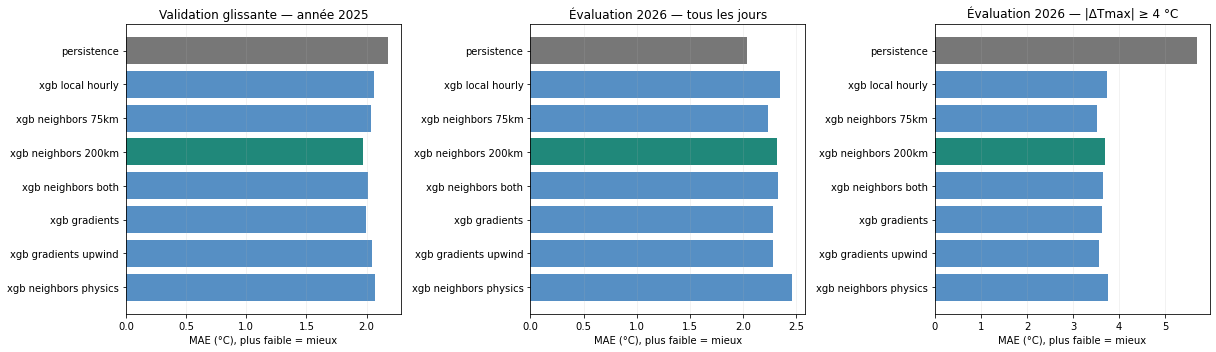

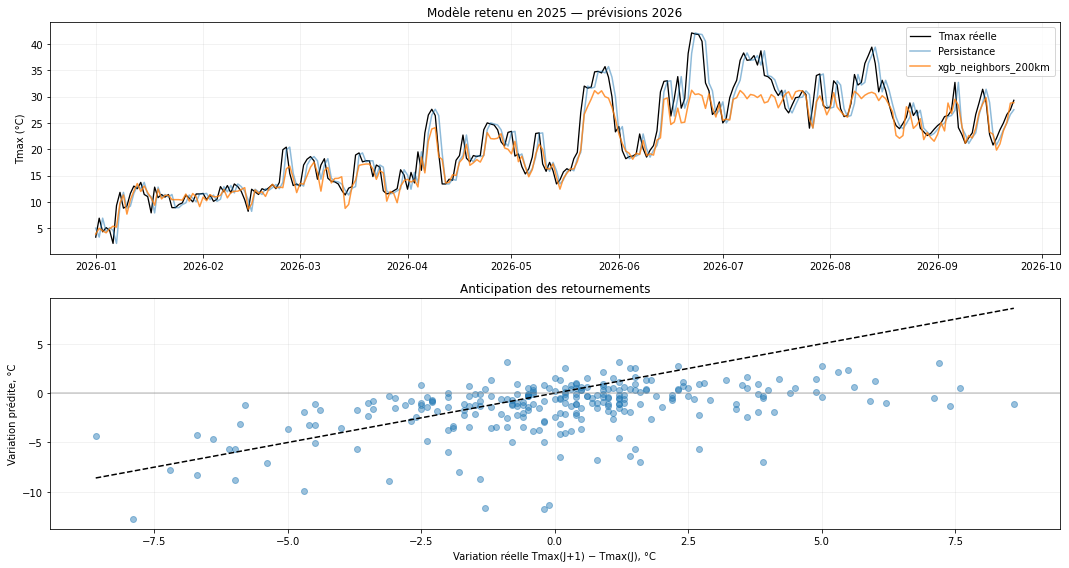

Diagnostic de décalage : vérité comparée à date_cible + décalage. -1 = la veille.


,MAE_truth_date_plus_-1_C,MAE_truth_date_plus_0_C,MAE_truth_date_plus_1_C
variant,,,
persistence,0.000,2.040,3.060
xgb_local_hourly,1.847,2.354,3.010
xgb_neighbors_75km,1.845,2.238,2.986
xgb_neighbors_200km,1.970,2.328,2.993
xgb_neighbors_both,2.007,2.340,3.019
xgb_gradients,1.811,2.286,2.982
xgb_gradients_upwind,1.816,2.292,3.001
xgb_neighbors_physics,2.138,2.471,3.120


Un minimum à -1 signale une ressemblance avec la veille ; il ne prouve pas une erreur de dates.
MAE par mois cible, mêmes jours pour tous les modèles :


variant,persistence,xgb_gradients,xgb_gradients_upwind,xgb_local_hourly,xgb_neighbors_200km,xgb_neighbors_75km,xgb_neighbors_both,xgb_neighbors_physics
month,,,,,,,,
2026-01,1.687,1.353,1.371,1.376,1.408,1.309,1.359,1.338
2026-02,1.454,1.214,1.198,1.303,1.225,1.185,1.241,1.235
2026-03,1.526,1.576,1.547,1.563,1.823,1.647,1.788,1.883
2026-04,2.423,2.110,2.089,2.027,2.435,2.023,2.425,2.528
2026-05,2.158,2.613,2.606,2.539,2.597,2.460,2.688,2.825
2026-06,2.770,3.512,3.437,3.517,3.743,3.441,3.767,4.033
2026-07,2.129,3.545,3.664,3.921,3.415,3.462,3.443,3.649
2026-08,2.045,2.795,2.833,2.957,2.349,2.783,2.431,2.725
2026-09,2.170,1.572,1.605,1.743,1.667,1.577,1.604,1.705


Les effectifs des fortes variations sont limités ; pas de conclusion causale sur les fronts météorologiques.


In [5]:
report(scores, predictions, lag_scores, intervals, selected, output)


## Géométrie du voisinage

Coordonnées des cellules réellement retournées, sans présumer une station de mesure.

,lat,lon
point,,
center,47.25,-1.50
local_east,47.25,-0.50
local_north,48.00,-1.50
local_south,46.50,-1.50
local_west,47.25,-2.50
regional_east,47.25,1.00
regional_north,49.00,-1.50
regional_south,45.50,-1.50
regional_west,47.25,-4.25


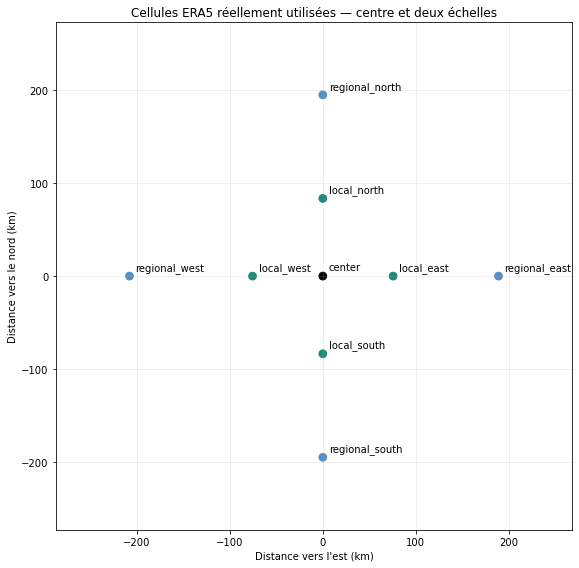

In [6]:
display(cells)
plot_cells(cells, output)


## Interprétation et limites

Un gain global sans gain sur les refroidissements ne valide pas l'hypothèse d'anticipation des fronts.
À l'inverse, un gain sur quelques pics peut être instable : regarder les effectifs, les trois fenêtres
2025 et les mois de 2026. Ne pas confondre mauvaise information, décalage d'alignement et faible
extrapolation du modèle. Cette étude ne mesure pas directement les fronts ni les masses d'air.
L'absence de gain avec ces variables ne prouve pas que toute information spatiale est inutile.

Avec moins de trois années et environ mille journées, les réseaux neuronaux ne sont pas la prochaine
étape automatique. Une confirmation sur des années supplémentaires et des prévisions archivées
disponibles à l'heure d'émission sera nécessaire avant une conclusion opérationnelle.

Sources : [Open-Meteo, réanalyse et paramètres](https://open-meteo.com/en/docs/historical-weather-api),
[évaluation temporelle](https://scikit-learn.org/stable/modules/cross_validation.html),
[complexité et régularisation XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html).

In [7]:
cv = summarize_cv(scores)
test = scores.loc[scores["window"].eq("test_2026")].set_index("variant")
print(f"Variante choisie en 2025 : {selected}")
print(f"MAE 2025 : {cv.loc[selected, 'MAE_C']:.3f} °C ; persistance : {cv.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 : {test.loc[selected, 'MAE_C']:.3f} °C ; persistance : {test.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 sur fortes variations : {test.loc[selected, 'MAE_large_changes_C']:.3f} °C ; n = {test.loc[selected, 'n_large_changes']}")
print(f"Traces et figures enregistrées dans {output.relative_to(PROJECT_ROOT)}")


Variante choisie en 2025 : xgb_neighbors_200km
MAE 2025 : 1.967 °C ; persistance : 2.176 °C
MAE 2026 : 2.321 °C ; persistance : 2.039 °C
MAE 2026 sur fortes variations : 3.685 °C ; n = 41
Traces et figures enregistrées dans experiments/results/03_spatial_information
